In [15]:
import pandas as pd

In [16]:
filepath = "../data/dataset.xlsx"
dataframe = pd.read_excel(filepath)
dataframe.shape

(319, 39)

obs 
- skriv hva et beslutningstre er
- hva root, split, leaf node og depth betyr
- hvorfor dyp tre kan gi overfitting

In [17]:
from sklearn.model_selection import train_test_split

X = dataframe.drop(columns=["Gallstone Status"])
y = dataframe["Gallstone Status"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (255, 38)
X_test: (64, 38)
y_train: (255,)
y_test: (64,)


In [18]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

print("Trening:", tree.score(X_train, y_train))
print("Test:", tree.score(X_test, y_test))
print("Dybde:", tree.get_depth())
print("Antall blader:", tree.get_n_leaves())

Trening: 1.0
Test: 0.65625
Dybde: 12
Antall blader: 41


In [19]:
from sklearn.model_selection import cross_val_score

for depth in range(1, 13):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    cv_scores = cross_val_score(model, X_train, y_train, cv=5)
    model.fit(X_train, y_train)
    print(depth, round(model.score(X_train, y_train), 3), round(cv_scores.mean(), 3))

1 0.749 0.722
2 0.761 0.69
3 0.816 0.694
4 0.859 0.694
5 0.929 0.675
6 0.953 0.651
7 0.965 0.663
8 0.98 0.663
9 0.984 0.651
10 0.992 0.671
11 0.996 0.667
12 1.0 0.682


I starten, før instruksjoner, stilte treet så mange spm det ville og endte opp på 12 stk. Dette resulterte i 100% rett på pasientene det øvde på, men kun 66% rett på nye pasienter. (Typ man pugger til en prøve og pugger svarene, der pugger man rett og får alt korrekt, men når den ekte prøven kommer får man bare 66% av svarene korrekt)
Deretter prøvde jeg med ulike trær hvor det fikk stille 1 til 12 spm (se på 1-12 kategorier)  - her viser svarene først hvordan den gjorde det på øvingspasientene og deretter hvordan den gjorde det på "prøveeksamen". De 255 øvingspasientene kommer fra train_test_split. Disse er igjen delt inn i 5 ulike grupper som har ca 51 psienter i hver. Da ble en gruppe gjemt bort hver gang og maskinen testet på den gruppen som om det var eksamen. 64 pasienter er uberørt som maskinen ikke får se på gjennom hele treningsperioden, kun senere helt til slutt (som en eksamen). 

Konklusjon: når treet får stille flere spørsmål er det best suksessrate ved 1 spørsmål. Her fikk den 72% rett. Vi kan se at mange variabler ikke egt har noe sammenheng med gallestein - som feks glukose og alder, dette er kun en hypotese som er hentet fra selve excel-filen. Et funn som kan vise til overfitting er at tallet stiger mot 100% for øvingspasientene, mens det synker på prøveeksamnene. 

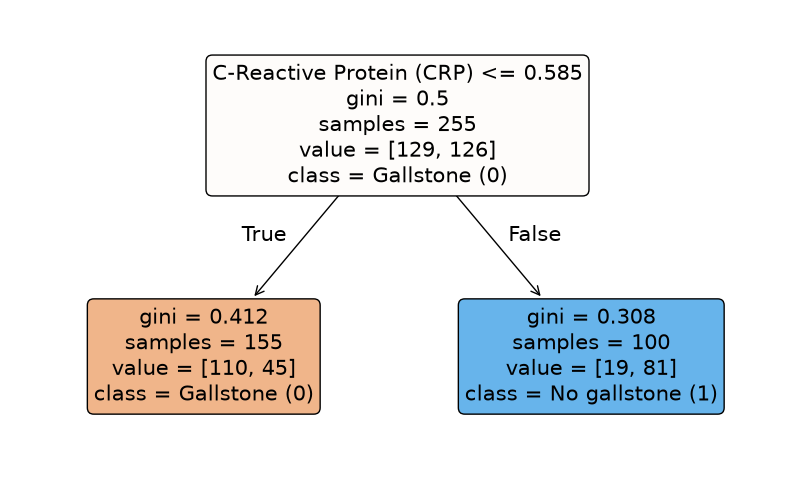

In [20]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

best_tree = DecisionTreeClassifier(max_depth=1, random_state=42)
best_tree.fit(X_train, y_train)

plt.figure(figsize=(10, 6))
plot_tree(best_tree, feature_names=X_train.columns, class_names=["Gallstone (0)", "No gallstone (1)"], filled=True, rounded=True)
plt.show()

Vi valgte treet som stiller et spm, det valgte å spørre om CRP er mindre eller lik 0.585. Det velges et spm sidne dette ga best resultat på kryssvalideringen (72%). Til venstre (true) får alle 155 beskjed om at de har gallestein, men 45 av disse har ikke gallestein. Til høyre er det 100 som får beskjed om at de ikke har det, selv om 19 stk faktisk har gallestein. Dette gjelder for treningspasientene - til sammen 255 stk.

Noe so, kan virke litt rart er at CRP måler høy betennelse i kroppen som er noe gallesteinsykdom medfører. UCI viser til at høy CRP (gruppe 1) = ikke gallestein", mens lav CRP (gruppe 0)= gallestein. Oversikten viser også at gruppe 1 hadde flere kvinner, mer kroppsfett og lavere vitamin D som alle er risikofaktorer for gallestein. 
Dette kan tyde på at UCI har beskrevet kodene feil vei, altså at 1 egentlig betyr gallestein. Dette må sjekkes i artikkelen før vi tolker resultatene.

In [21]:
from sklearn.model_selection import GridSearchCV

params = {"max_depth": [1, 2, 3, 4, 5, 6], "min_samples_leaf": [1, 5, 10, 20, 30]}

search = GridSearchCV(DecisionTreeClassifier(random_state=42), params, cv=5)
search.fit(X_train, y_train)

print("Beste innstillinger:", search.best_params_)
print("Beste CV-resultat:", round(search.best_score_, 3))

Beste innstillinger: {'max_depth': 1, 'min_samples_leaf': 1}
Beste CV-resultat: 0.722
